# Analyse des résultats 
Ce notebook ne fait **aucun entraînement** : il lit uniquement les petits fichiers JSON de `results/`
(copiés depuis le volume Modal `food101-ckpt`) et produit :

1. **Fig. 4** — accuracy *val* par epoch des 4 modèles (image, texte, late concat, early) ;
2. **Table VII** — accuracy test de nos 4 modèles à côté de l'article ;
3. **Table VI** — les 4 stratégies de late fusion à côté de l'article ;
4. **Early fusion** — moyenne ± écart-type sur 3 seeds.

Les figures sont sauvegardées en PNG dans `results/figures/`, les tables en CSV dans `results/`.

## 1. Imports et chemins

- Le notebook est dans `notebooks/`, donc les résultats sont dans `../results/`.
- `modal volume get food101-ckpt results results/` crée un sous-dossier `results/results/` quand
  `results/` existe déjà : `find_results_dir` regarde aux deux endroits et prend celui qui contient
  `image.json`.
- `FIG_DIR` est créé s'il n'existe pas (`exist_ok=True`, l'équivalent de `mkdir -p`).

In [10]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..")                       # project root, seen from notebooks/
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def find_results_dir(root: Path) -> Path:
    # results/ or results/results/ (nested copy from `modal volume get`)
    for candidate in (root / "results", root / "results" / "results"):
        if (candidate / "image.json").exists():
            return candidate
    raise FileNotFoundError("image.json not found in results/ or results/results/")


RESULTS_DIR = find_results_dir(ROOT)
print("results read from:", RESULTS_DIR.resolve())
print(sorted(p.name for p in RESULTS_DIR.glob("*.json")))

results read from: /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 1/codev1/results/results
['early.json', 'image.json', 'image_smoke.json', 'late_concat.json', 'late_max.json', 'late_sum.json', 'late_weighted.json', 'text.json', 'text_smoke.json']


## 2. Chargement des runs

- `load_run(name)` lit `results/<name>.json` : `config`, `history` (une ligne par epoch), et pour
  les fusions `best_epoch`, `best_val_acc`, `test_acc`, `test_loss`.
- **Accuracy test des modèles image et texte** : `train.py` ne touche jamais le test, donc
  `image.json` / `text.json` n'en ont pas. On la lit dans le JSON d'une fusion : `train_fusion.py` la
  calcule à partir des softmax en cache des `best.pt` (clé `baseline_test_acc`, ou
  `unimodal_test_acc` pour les runs lancés avant le renommage).
- **Contrôle de cohérence** : tous les runs de fusion doivent avoir été entraînés sur des features
  extraites des *mêmes* checkpoints (`feature_checkpoints`), sinon la comparaison n'a pas de sens.

In [11]:
def load_run(name: str) -> dict:
    with open(RESULTS_DIR / f"{name}.json") as f:
        return json.load(f)


def unimodal_test_acc(run: dict) -> dict:
    # image / text test accuracy stored by train_fusion.py (key renamed at some point)
    return run.get("baseline_test_acc") or run["unimodal_test_acc"]


runs = {name: load_run(name) for name in ("image", "text", "late_concat", "early")}
late_runs = {m: load_run(f"late_{m}") for m in PAPER_TABLE_VI}

fusion_runs = {**{f"late_{m}": r for m, r in late_runs.items()}, "early": runs["early"]}
checkpoints = {name: json.dumps(r["feature_checkpoints"], sort_keys=True) for name, r in fusion_runs.items()}
if len(set(checkpoints.values())) == 1:
    print("OK: all fusion runs use features from the same checkpoints:")
    print(" ", runs["early"]["feature_checkpoints"])
else:
    print("WARNING: fusion runs use features from different checkpoints:", checkpoints)

OK: all fusion runs use features from the same checkpoints:
  {'image': {'path': '/ckpt/image/best.pt', 'epoch': 24, 'val_acc': 0.7272727272727273}, 'text': {'path': '/ckpt/text/best.pt', 'epoch': 24, 'val_acc': 0.8487790526625478}}


## 3. Fig. Accuracy val par epoch

- Une courbe par modèle : `history[i]["val_acc"]` en fonction de `history[i]["epoch"]`.
- Le point marque la **meilleure epoch sur val** : c'est celle dont les poids sont dans `best.pt` et
  qui sert à l'évaluation test.
- **Différence avec l'article** : la Fig. 4 de l'article trace l'accuracy *test* par epoch. Ici on
  trace le *val*, car le test ne doit servir qu'aux chiffres finaux (sinon regarder la courbe test
  pour choisir l'epoch revient à régler sur le test).
- Mêmes couleurs que l'article : image bleu, texte rouge, late vert, early violet.
- Les courbes n'ont pas la même longueur : chaque run s'arrête à `epochs` ou plus tôt par early
  stopping.

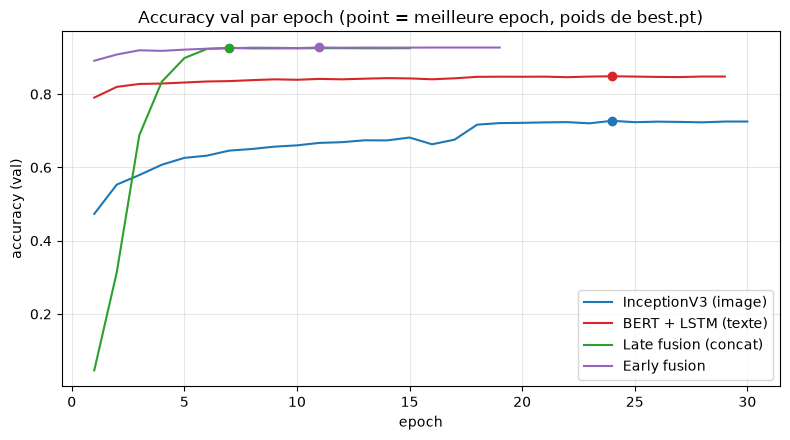

In [12]:
CURVES = {   # run name -> (label, color as in the paper's Fig. 4)
    "image": ("InceptionV3 (image)", "tab:blue"),
    "text": ("BERT + LSTM (texte)", "tab:red"),
    "late_concat": ("Late fusion (concat)", "tab:green"),
    "early": ("Early fusion", "tab:purple"),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (label, color) in CURVES.items():
    history = pd.DataFrame(runs[name]["history"])
    ax.plot(history["epoch"], history["val_acc"], color=color, label=label)
    best = history.loc[history["val_acc"].idxmax()]
    ax.scatter(best["epoch"], best["val_acc"], color=color, zorder=3)

ax.set_xlabel("epoch")
ax.set_ylabel("accuracy (val)")
ax.set_title("Accuracy val par epoch (point = meilleure epoch, poids de best.pt)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_val_accuracy.png", dpi=150)
plt.show()

## 3. Early fusion — loss train / val 

- **Train** et **val** : une valeur par epoch, lues dans `history` (`train_loss`, `val_loss`).
- Lignes orange : baisses du learning rate (0.01 → 0.001 → 0.0001, scheduler *plateau* sur val).
- **Échelle log** : la loss train va de 2.0 à 0.03, la val reste autour de 0.36 ; en échelle linéaire
  les deux courbes seraient écrasées.
- **Pourquoi la train loss est-elle 10× plus basse que la val ?**
  - À l'epoch 1, la train loss est une *moyenne pendant l'epoch* (le modèle part de zéro), alors que la
    val est mesurée *en fin d'epoch* : d'où train > val au début.
  - Ensuite, train ≪ val surtout parce que les **features train sont « trop faciles »** : InceptionV3
    et BERT + LSTM ont été entraînés sur ces mêmes images et titres, donc leurs features train sont
    plus séparables que celles de val/test (images jamais vues). La tête de fusion voit un train
    plus facile que la réalité. C'est le biais classique du *stacking* quand on réutilise le même
    train à deux niveaux. (La dropout 0.4, active seulement en train, pousse au contraire la train
    loss vers le haut : elle n'explique pas l'écart.)
  - Val et test restent proches (0.36 vs 0.34) : la val est donc un bon substitut du test pour
    choisir l'epoch.

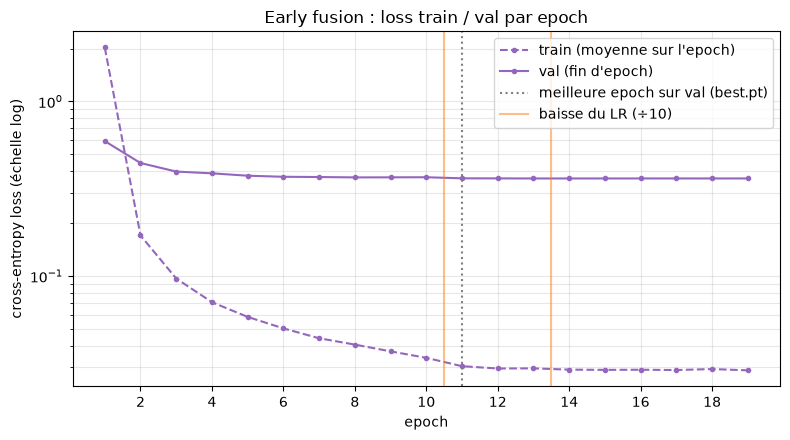

best epoch 11: train loss 0.030, val loss 0.362, test loss 0.342


In [14]:
from matplotlib.ticker import MaxNLocator

early = runs["early"]
history = pd.DataFrame(early["history"])                     # one row per epoch
best_epoch = early["best_epoch"]
lr_drops = history.loc[history["lr"].diff() < 0, "epoch"]   # first epoch at each new (lower) LR

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(history["epoch"], history["train_loss"], color="tab:purple", linestyle="--",
        marker="o", markersize=3, label="train (moyenne sur l'epoch)")
ax.plot(history["epoch"], history["val_loss"], color="tab:purple",
        marker="o", markersize=3, label="val (fin d'epoch)")
ax.axvline(best_epoch, color="gray", linestyle=":", label="meilleure epoch sur val (best.pt)")
for i, epoch in enumerate(lr_drops):
    ax.axvline(epoch - 0.5, color="tab:orange", alpha=0.5,
               label="baisse du LR (÷10)" if i == 0 else None)

ax.set_yscale("log")    # train loss spans 2.0 -> 0.03: log scale keeps both curves readable
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy loss (échelle log)")
ax.set_title("Early fusion : loss train / val par epoch")
ax.grid(alpha=0.3, which="both")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "early_fusion_loss.png", dpi=150)
plt.show()

at_best = history.loc[history["epoch"] == best_epoch].iloc[0]
print(f"best epoch {best_epoch}: train loss {at_best['train_loss']:.3f}, "
      f"val loss {at_best['val_loss']:.3f}, test loss {early['test_loss']:.3f}")

## Accuracy test des 4 modèles

In [15]:
unimodal = unimodal_test_acc(runs["early"])
ours = {
    "image": unimodal["image"],
    "text": unimodal["text"],
    "late_concat": runs["late_concat"]["test_acc"],
    "early": runs["early"]["test_acc"],
}
table_vii = pd.DataFrame({
    "modèle": ["Images (InceptionV3)", "Texte (BERT + LSTM)", "Late fusion (concat)", "Early fusion"],
    "accuracy (%)": [100 * ours[k] for k in PAPER_TABLE_VII],
})
table_vii.to_csv(RESULTS_DIR / "table_vii.csv", index=False)
table_vii.round(2)

,modèle,accuracy (%)
0,Images (InceptionV3),72.16
1,Texte (BERT + LSTM),85.38
2,Late fusion (concat),92.72
3,Early fusion,92.70


## Les 4 stratégies de late fusion

- Une ligne par mode de fusion (`late_<merge>.json`) : accuracy et loss test, plus l'epoch choisie
  sur val.
- `alpha` (mode `weighted` seulement) : poids appris sur le softmax **image**
  (le texte reçoit `1 − alpha`).
- Ligne supplémentaire **« moyenne (sans entraînement) »** : `(p_img + p_txt) / 2`, sans MLP. Elle
  n'est pas dans l'article, mais elle montre ce que le MLP de fusion apporte (ou non) par rapport à
  une simple moyenne.
- Les loss test ne sont comparables à l'article qu'à titre indicatif : même fonction
  (cross-entropy), mais des modèles de base différents.

In [22]:
MERGE_NAMES = {"sum": "Sum", "max": "Maximum", "weighted": "Weighted Ensemble", "concat": "Concatenation"}

rows = []
for merge, (paper_acc, paper_loss) in PAPER_TABLE_VI.items():
    run = late_runs[merge]
    rows.append({
        "fusion": MERGE_NAMES[merge],
        "acc (%)": 100 * run["test_acc"],
        "loss": run["test_loss"],
        "best epoch (val)": run["best_epoch"],
    })

table_vi = pd.DataFrame(rows)
table_vi.to_csv(RESULTS_DIR / "table_vi.csv", index=False)
table_vi.round(3)

,fusion,acc (%),loss,best epoch (val)
0,Sum,93.102,0.430,8
1,Maximum,92.776,0.458,14
2,Weighted Ensemble,88.303,3.307,6
3,Concatenation,92.723,0.688,7
